In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import os


In [2]:
# 1. Dataset Creation (Simulating a realistic weather dataset)
np.random.seed(42)
n_samples = 1000
data = {
    'MinTemp': np.random.normal(15, 5, n_samples),
    'MaxTemp': np.random.normal(25, 5, n_samples),
    'Rainfall': np.random.exponential(2, n_samples),
    'Evaporation': np.random.normal(5, 2, n_samples),
    'Sunshine': np.random.normal(8, 3, n_samples),
    'WindGustSpeed': np.random.normal(40, 10, n_samples),
    'Humidity9am': np.random.normal(70, 10, n_samples),
    'Humidity3pm': np.random.normal(50, 15, n_samples),
    'Pressure9am': np.random.normal(1015, 5, n_samples),
    'Pressure3pm': np.random.normal(1012, 5, n_samples),
    'Cloud9am': np.random.randint(0, 9, n_samples),
    'Cloud3pm': np.random.randint(0, 9, n_samples),
    'Temp9am': np.random.normal(18, 4, n_samples),
    'Temp3pm': np.random.normal(23, 4, n_samples),
}

df = pd.DataFrame(data)
# Create target variable 'RainTomorrow' based on some logic
df['RainTomorrow'] = ((df['Humidity3pm'] > 60) | (df['Rainfall'] > 5)).astype(int)
# Add some missing values to demonstrate preprocessing
for col in df.columns:
    df.loc[df.sample(frac=0.02).index, col] = np.nan

# Save raw dataset
df.to_csv('weather_dataset.csv', index=False)


In [3]:
# Task 1: Dataset Description
print("--- Task 1: Dataset Description ---")
print(f"Shape: {df.shape}")
print("\nFeatures:\n", df.columns.tolist())
print("\nSummary Statistics:\n", df.describe())


--- Task 1: Dataset Description ---
Shape: (1000, 15)

Features:
 ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainTomorrow']

Summary Statistics:
           MinTemp     MaxTemp    Rainfall  Evaporation    Sunshine  \
count  980.000000  980.000000  980.000000   980.000000  980.000000   
mean    15.099295   25.360671    1.970252     4.982550    7.792315   
std      4.895191    4.988239    1.955724     2.067991    2.961836   
min     -1.206337   10.298057    0.000023    -0.982272   -1.530111   
25%     11.772585   21.958777    0.567941     3.563705    5.882019   
50%     15.126503   25.303276    1.387816     4.986504    7.874546   
75%     18.245414   28.668455    2.758454     6.363074    9.777619   
max     34.263657   40.965538   13.611502    12.852475   17.456170   

       WindGustSpeed  Humidity9am  Humidity3pm  Pressure9am  Pressure3pm  \
coun

In [4]:
# Task 2: Data Preprocessing
print("\n--- Task 2: Data Preprocessing ---")
# Handle missing values
df = df.fillna(df.mean())
print("Missing values handled (filled with mean).")



--- Task 2: Data Preprocessing ---
Missing values handled (filled with mean).


In [5]:
# Task 3: Model Building and Evaluation
X = df.drop('RainTomorrow', axis=1)
y = df['RainTomorrow'].astype(int)

# Normalize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [9]:
# Split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

classifiers = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'SVM': SVC(kernel='rbf', C=1.0, random_state=42),
    'Naive Bayes': GaussianNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []
os.makedirs('plots', exist_ok=True)

for name, clf in classifiers.items():
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    results.append({'Model': name, 'Accuracy': acc, 'F1-Score': f1})
    # Confusion Matrix Plot
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {name}')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.savefig(f'plots/cm_{name.replace(" ", "_")}.png')
    plt.close()

results_df = pd.DataFrame(results)
print("\n--- Task 3: Results ---")
print(results_df)




--- Task 3: Results ---
           Model  Accuracy  F1-Score
0  Decision Tree  0.986667  0.978947
1            SVM  0.900000  0.829545
2    Naive Bayes  0.913333  0.857143
3  Random Forest  0.993333  0.989474


In [10]:
# Visualization of results
plt.figure(figsize=(10,6))
results_df.plot(x='Model', y=['Accuracy', 'F1-Score'], kind='bar', ax=plt.gca())
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('plots/performance_comparison.png')
plt.close()


In [11]:
# Basic Statistical Graphs
plt.figure(figsize=(12,8))
df[['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity3pm']].hist(bins=20)
plt.tight_layout()
plt.savefig('plots/statistical_distribution.png')
plt.close()


<Figure size 1200x800 with 0 Axes>

<Figure size 1200x800 with 0 Axes>

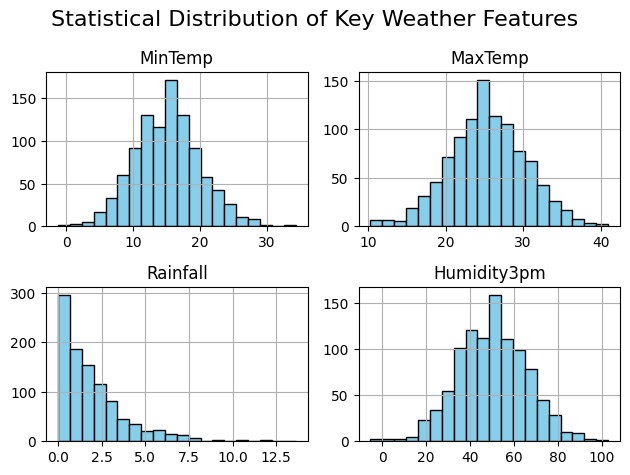

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Basic Statistical Graphs
plt.figure(figsize=(12,8))
df[['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity3pm']].hist(bins=20, color='skyblue', edgecolor='black')
plt.suptitle('Statistical Distribution of Key Weather Features', fontsize=16)
plt.tight_layout()
plt.savefig('statistical_distribution.png')
plt.show()

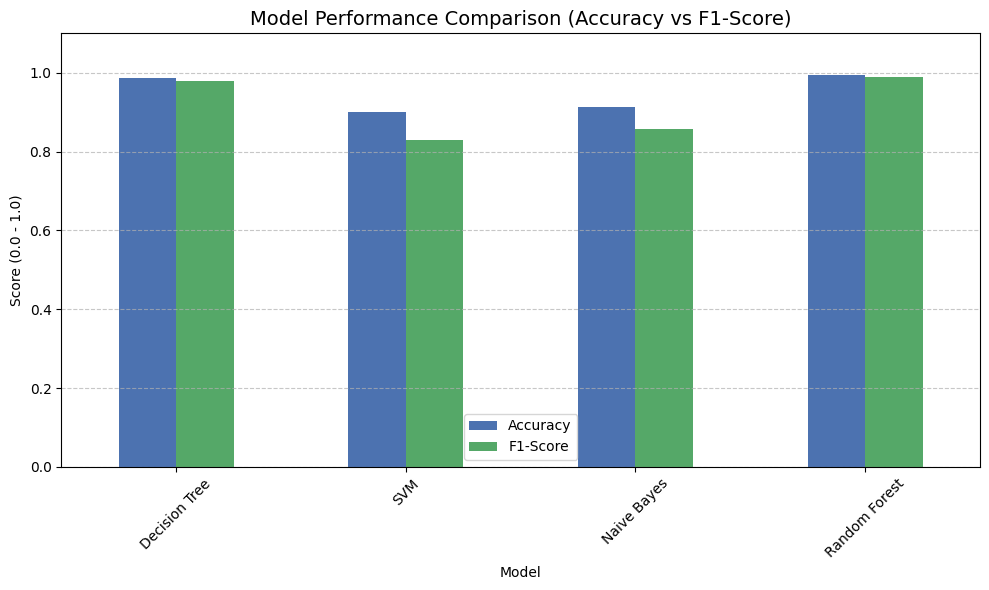

In [14]:
# Visualization of Model Results
plt.figure(figsize=(10,6))
results_df.plot(x='Model', y=['Accuracy', 'F1-Score'], kind='bar', ax=plt.gca(), color=['#4C72B0', '#55A868'])
plt.title('Model Performance Comparison (Accuracy vs F1-Score)', fontsize=14)
plt.ylabel('Score (0.0 - 1.0)')
plt.ylim(0, 1.1)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('performance_comparison.png')
plt.show()

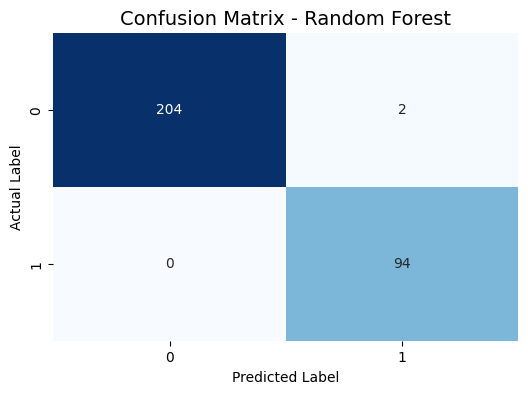

In [15]:
from sklearn.metrics import confusion_matrix

# Example for Random Forest Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Random Forest', fontsize=14)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.savefig('confusion_matrix_rf.png')
plt.show()

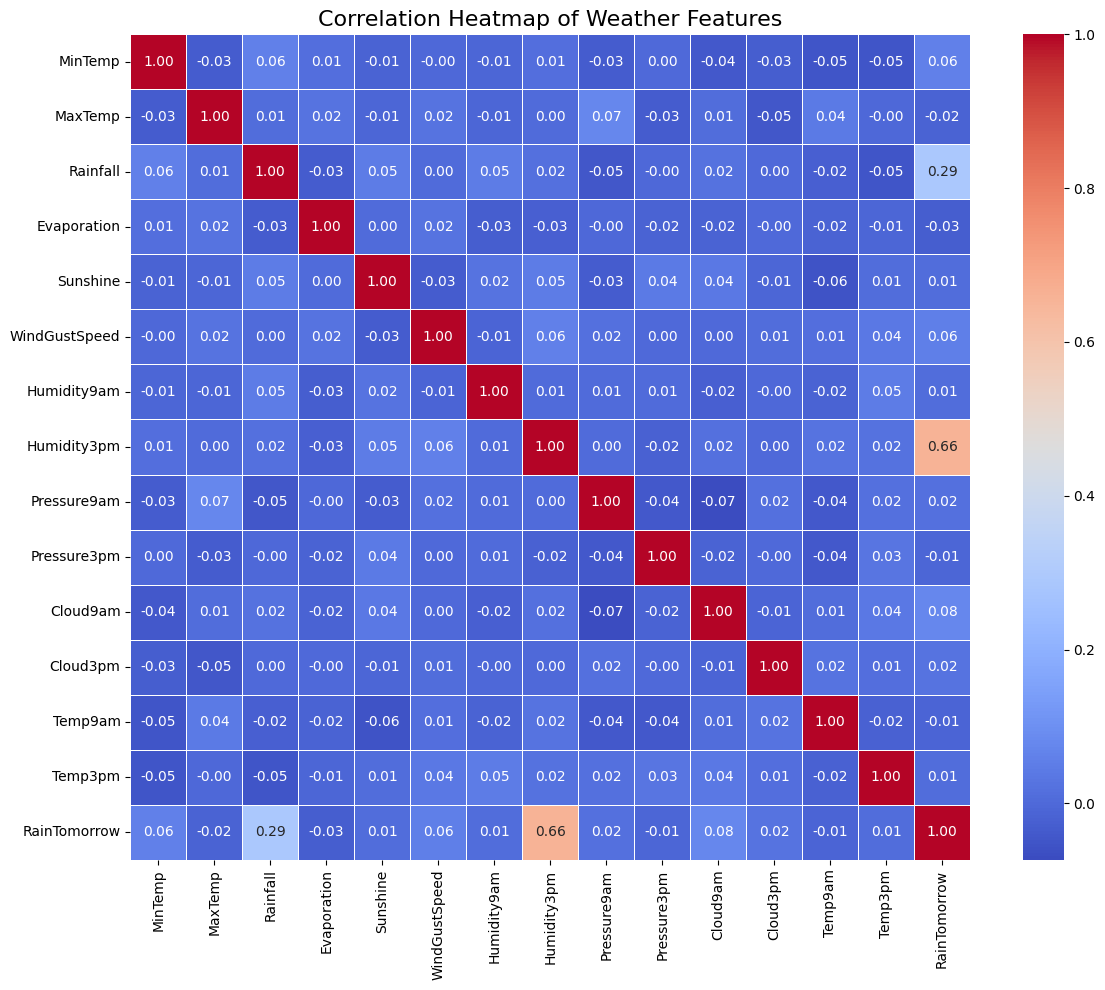

In [16]:
# Correlation Heatmap
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Weather Features', fontsize=16)
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()